In [55]:
%load_ext autoreload
%autoreload 2
import os

#import cordex as cx
import geopandas as gpd
from cartopy import crs as crs
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
wkd = os.getcwd()
wkd

'/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/COUNTRY_MAPS'

In [38]:
gerics_orange = (234/255, 129/255, 0)

open shape files 

#### Download the shape files for the country you want from diva-gis
downloaded from https://diva-gis.org/data.html 

##### License:
*These data were extracted from the GADM database (www.gadm.org), version 2.5, July 2015. They can be used for non-commercial purposes only.  It is
not allowed to redistribute these data, or use them for commercial purposes, without prior consent.*


In [39]:
# local directory, where I stored the files 

home='/home/g/g300047/GITLAB/climate_fact_data/'
# Admin regions
adm_reg_dir='/work/ch0636/g300047/cicles/regions/DIVA-GIS-DOWNLOAD/adm/'
# Burkina Faso + 3 other regions (ISO3 codes); update as needed
adm_regions = ['BFA', 'CIV', 'TGO']  # TGO has only adm0..adm2
levels_per_iso = {'TGO': 3}  # number of levels (range upper bound)

admfiles = [
    os.path.join(adm_reg_dir, f'{iso}_adm{lvl}.shp')
    for iso in adm_regions
    for lvl in range(levels_per_iso.get(iso, 4))  # others: adm0..adm3
]

# Test read one file
#infile =os.path.join(adm_reg_dir, admfiles[2])
#shpfile= gpd.read_file(infile)  # example: Burkina Faso adm0


In [40]:
# Plot directory:

plotdir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/COUNTRY_ADMIT'
if not os.path.exists(plotdir):
    os.makedirs(plotdir)
    

In [48]:
# Read, select columns and merge
adm_selected_merged = []
selected_columns = ['ISO','NAME_0', 'NAME_1', 'NAME_2', 'geometry']
for f in admfiles:
    gdf = gpd.read_file(f)
    # keep only the columns that exist in this file
    cols_present = [c for c in selected_columns if c in gdf.columns]
    gdf_sel = gdf[cols_present].copy()

    # add missing columns so we can concatenate consistently
    for c in selected_columns:
        if c not in gdf_sel.columns:
            gdf_sel[c] = None

    # ensure column order
    gdf_sel = gdf_sel[selected_columns]
    #print(gdf_sel.head(3))
    adm_selected_merged.append(gdf_sel)


# Save to a single shapefile (optional)
output_adm_selected_shp = os.path.join(adm_reg_dir, 'adm_selected_merged_BKF_TGO_CIV.shp')
os.makedirs(os.path.dirname(output_adm_selected_shp), exist_ok=True)

# determine a valid CRS from inputs (avoid using cartopy.crs alias named 'crs')
source_crs = next((g.crs for g in adm_selected_merged if getattr(g, "crs", None)), None)

# concatenate the list into a single GeoDataFrame before saving
merged_df = pd.concat(adm_selected_merged, ignore_index=True)
merged_gdf = gpd.GeoDataFrame(merged_df, geometry='geometry', crs=source_crs)
merged_gdf.to_file(output_adm_selected_shp)

# preview the first rows of the concatenated result
merged_df.head(3)

,ISO,NAME_0,NAME_1,NAME_2,geometry
0,BFA,Burkina Faso,None,None,"POLYGON ((-0.45567 15.08082, -0.45128 15.07672..."
1,BFA,Burkina Faso,Boucle du Mouhoun,None,"POLYGON ((-3.20985 13.69655, -3.18562 13.68533..."
2,BFA,Burkina Faso,Cascades,None,"POLYGON ((-5.2595 10.85468, -5.25912 10.85359,..."


In [50]:
shpfile=gpd.read_file(output_adm_selected_shp)
# plot each country (unique NAME_0) and save
for country in shpfile['NAME_0'].dropna().unique():
    sub = shpfile[shpfile['NAME_0'] == country]
    fig, ax = plt.subplots(figsize=(8, 8))
    shpfile.plot(ax=ax, color='lightgrey', edgecolor='black', linewidth=0.3, alpha=0.5)
    sub.plot(ax=ax, color=gerics_orange, edgecolor='black', linewidth=0.8)
    ax.set_axis_off()
    safe_name = country.replace(' ', '_').replace("'", '').replace('’', '')
    outpath = os.path.join(plotdir, f'ADM_{safe_name}.png')
    fig.savefig(outpath, dpi=300, bbox_inches='tight')
    plt.close(fig)
#shpfile.plot(figsize=(8, 8), color='lightgrey', edgecolor='black', linewidth=0.4)

<Axes: >

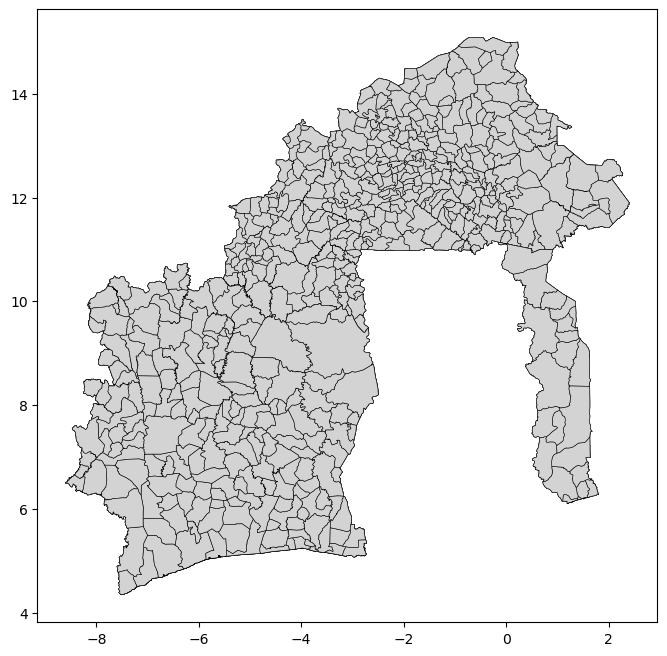

In [47]:
shpfile.plot(figsize=(8, 8), color='lightgrey', edgecolor='black', linewidth=0.4)

Now open ororgraphie file of ARF-22 to see if the areas are too small or OK

In [79]:
color_list = [ '#a6cee3','#004529',
              '#006837','#238443','#41ab5d','#78c679','#addd8e',
              '#d9f0a3','#f7fcb9','#ffffe5','#fdd0a2',
              '#fdae6b','#fd8d3c','#f16913','#d94801','#a63603','#7f2704']
color_levels = [1, 100, 200, 300, 400, 500, 600, 700, 800,
                900, 1000, 1200, 1400, 1600, 1800, 2000]



Es müsste korrecterweise noch die Landsee maske eingelesen werden

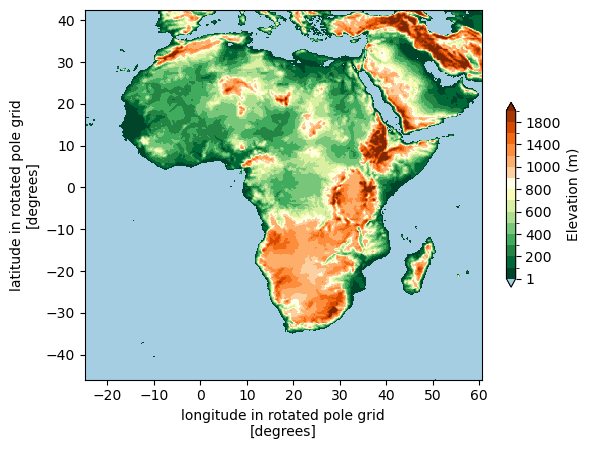

In [80]:
orog_file='/work/ch0636/eddy/pool/sims/cordex/afr22/fx/orog/orog_AFR-22_MPI-M-MPI-ESM-LR_historical_r0i0p0_CLMcom-KIT-CCLM5-0-15_v1_fx.nc'
orog_ds = xr.open_dataset(orog_file)
orog_ds['orog'].plot(
    colors=color_list, 
    levels=color_levels, 
    extend='both', 
    cbar_kwargs={'label': 'Elevation (m)', 'shrink': 0.5}, 
    cmap=None,
    )

In [81]:
def only_land_points(data):
    '''Mask out ocean data using land-sea mask if available'''

    # Land sea mask
    lsm=xr.open_dataset('/work/ch0636/g300047/cicles/lsm_afr22_common_ohne_pur_wasser.nc')

    land_mask = lsm['sftlf'].where(lsm['sftlf'] == 1)
    data_variable= data.where(land_mask.values == 1)

    return data_variable


<GeoAxes: xlabel='longitude in rotated pole grid\n[degrees]', ylabel='latitude in rotated pole grid\n[degrees]'>

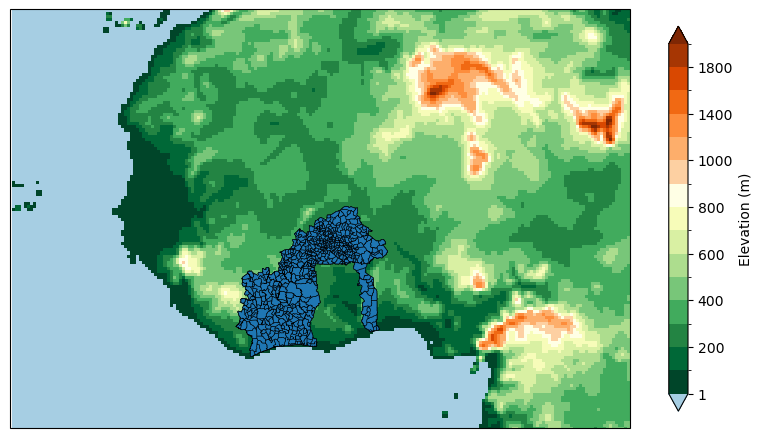

In [85]:
# 
#Only west Afrika
fig,ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': crs.PlateCarree()})
ax.set_extent([-25, 20, -0.75, 27.3])

im=orog_ds['orog'].plot(
    ax=ax,
    transform=crs.PlateCarree(),
    colors=color_list, 
    levels=color_levels, 
    extend='both', 
    cbar_kwargs={'label': 'Elevation (m)', 'shrink': 0.5}, 
    cmap=None,
    )

shpfile.plot(ax=ax, edgecolor='black', linewidth=0.4)

In [83]:
# Overlay shapefile boundaries on top of the existing orography plot (uses `ax` from cell 15)
if 'ax' in globals():
    shpfile.boundary.plot(ax=ax, color='black', linewidth=0.4)
else:
    # Fallback: create a new map if `ax` is not available
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': crs.PlateCarree()})
    ax.set_extent([-25, 20, -0.75, 27.3])
    orog_ds['orog'].plot(
        ax=ax,
        transform=crs.PlateCarree(),
        colors=color_list,
        levels=color_levels,
        extend='both',
        cbar_kwargs={'label': 'Elevation (m)', 'shrink': 0.5},
        cmap=None,
    )
    shpfile.boundary.plot(ax=ax, color='black', linewidth=0.4)